# 03 · Research-Domain Classification and Keywords

**Use Case 3: Research Paper Analysis and Recommendation System**  
**Owner:** Member B (classification lead)

**Goal:** Predict a paper's primary research domain (6 CS categories) and extract its keywords.

**Basic techniques (Weeks 1–6)**
- TF-IDF keyword extraction (top-weighted terms per paper and per category)
- Traditional classification: Naive Bayes and Logistic Regression on BoW vs TF-IDF features

**Advanced techniques (Weeks 7–12)**
- Fine-tune DistilBERT/SciBERT **or** zero/few-shot LLM classification
- Optional: ensemble of the best traditional model and the transformer

**Evaluation:** Accuracy, macro-F1 and a confusion matrix on the shared test split for every model. Discuss cross-listed papers (about 54% of the sample) as a source of error.

**Report section:** Classification; the comparative-analysis table across all members (~1,000 words).

## Setup

Run `01_data_loading_and_sampling.ipynb` first. Always evaluate on `test_df`.

In [1]:
from utils import load_sample, load_split

df = load_sample()
train_df, test_df = load_split(df)
print(f"all={len(df):,}  train={len(train_df):,}  test={len(test_df):,}")
train_df[["id", "primary_category", "title"]].head()

all=12,000  train=9,600  test=2,400


,id,primary_category,title
0,2404.00934,cs.CL,ChatGLM-RLHF: Practices of Aligning Large Lang...
1,2304.01712,cs.CL,Rumour Detection and Analysis on Twitter
2,2509.24120,cs.CL,EduVidQA: Generating and Evaluating Long-form ...
3,1706.03747,cs.CL,Acoustic data-driven lexicon learning based on...
4,1805.04793,cs.CL,Coarse-to-Fine Decoding for Neural Semantic Pa...


In [2]:
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
transformers.logging.set_verbosity_error()
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.naive_bayes import MultinomialNB

import classify as clf
from extraction import clean_text
from utils import save_results, ARTIFACTS_DIR

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

CATEGORIES = clf.CATEGORIES
y_train = train_df["primary_category"]
y_test = test_df["primary_category"]

# Sizes and models for the slower advanced parts (subsets, as agreed in the team plan)
ZERO_SHOT_N = 500             # W7 zero-shot on 500 test papers
FINETUNE_TRAIN_N = 3000       # W9 DistilBERT fine-tune on 3,000 training papers, 1 epoch
LLM_N = 200                   # W9 few-shot LLM classifier on 200 test papers
ZERO_SHOT_MODEL = "sileod/deberta-v3-base-tasksource-nli"   # same model as the Week 7 practical
DISTILBERT = "distilbert-base-uncased"                      # Week 6 tokenizer and Week 9 fine-tuning model

HAS_GPU = torch.cuda.is_available()
print("GPU available:", HAS_GPU, "|", torch.cuda.get_device_name(0) if HAS_GPU else "CPU only")
results = {"models": []}      # one row per model; saved with save_results("03", ...) at the end

GPU available: True | NVIDIA GeForce RTX 4060 Laptop GPU


## TF-IDF keywords

Week 4 TF-IDF, fitted on the training papers only (after `clean_text` from Part A removes LaTeX). A domain's keywords are the terms with the highest **average** TF-IDF weight over that domain's papers; a paper's keywords are its own highest-weighted terms. Unigrams and bigrams are used so phrases like "language models" survive.

> **Justification.** TF-IDF (Week 4) gives high weight to words that are frequent in one paper but rare across the corpus, which is close to what a keyword is. Averaging the weights over a category gives each domain a vocabulary we can check by eye (cs.CR: security, attacks, privacy), and the same weighting is the feature set for the classifiers below. Bigrams keep phrases like "language models" together.

In [3]:
keyword_vectoriser = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5,
                                     sublinear_tf=True, ngram_range=(1, 2))
# clean_text (from extraction.py) strips LaTeX such as \textbf{...} so it does not show up as a keyword
X_keywords = keyword_vectoriser.fit_transform(train_df["text"].map(clean_text))
terms = keyword_vectoriser.get_feature_names_out()

domain_keywords = {}
for category in CATEGORIES:
    rows = np.where(y_train.values == category)[0]
    mean_weights = np.asarray(X_keywords[rows].mean(axis=0)).ravel()
    best = np.argsort(mean_weights)[::-1][:10]
    domain_keywords[category] = [terms[j] for j in best]

results["domain_keywords"] = domain_keywords
pd.DataFrame(domain_keywords)

,cs.AI,cs.CL,cs.CR,cs.CV,cs.IR,cs.LG
0,agent,language,security,image,recommendation,learning
1,reasoning,models,attacks,images,user,data
2,ai,language models,privacy,3d,retrieval,model
3,agents,llms,attack,object,search,neural
4,models,model,data,model,based,models
5,model,text,based,method,systems,training
6,learning,large,secure,methods,recommender,networks
7,based,large language,paper,visual,item,based
8,language,tasks,detection,video,information,deep
9,knowledge,task,blockchain,learning,users,methods


In [4]:
# Keywords of three individual test papers
for _, row in test_df.sample(n=3, random_state=SEED).iterrows():
    weights = keyword_vectoriser.transform([clean_text(row["text"])]).toarray().ravel()
    best = np.argsort(weights)[::-1][:6]
    print(f"[{row['primary_category']}] {row['title']}")
    print("   ->", [terms[j] for j in best if weights[j] > 0], "\n")

[cs.CR] The Right to be Forgotten in Federated Learning: An Efficient Realization with Rapid Retraining
   -> ['unlearning', 'holders', 'machine unlearning', 'data holders', 'fl', 'right forgotten'] 

[cs.IR] Sequential Recommendation via Stochastic Self-Attention
   -> ['start items', 'transitivity', 'self attention', 'dot product', 'dot', 'items'] 

[cs.LG] A Generative Neural Annealer for Black-Box Combinatorial Optimization
   -> ['temperatures', 'black box', 'black', 'combinatorial', 'combinatorial optimization', 'box'] 



## BoW / TF-IDF + NB / LogReg baselines

Week 5 pipeline: Multinomial Naive Bayes on BoW counts and on TF-IDF, Logistic Regression on TF-IDF (same unigram vocabulary, so only the model or the weighting changes), plus Logistic Regression on unigrams + bigrams. Classes are balanced (1,600 train / 400 test each), so **macro-F1** is the main metric next to accuracy.

> **Justification.** Naive Bayes and Logistic Regression (Week 5) train in seconds, need no GPU and can be inspected, so they set the bar every later model has to clear. Each row changes one thing (counts vs TF-IDF, NB vs LogReg, unigrams vs bigrams), so any gain can be traced to that change. The six classes are balanced, which is why accuracy and macro-F1 come out almost identical.

In [5]:
def evaluate(y_true, y_pred, model_name, n_note=""):
    """Accuracy and macro precision/recall/F1 (adapted from evaluate_model in the Week 5 practical)."""
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=CATEGORIES, average="macro", zero_division=0)   # labels=: an "unparsed" LLM answer never becomes a 7th class
    row = {"model": model_name, "test_papers": len(y_true), "accuracy": round(accuracy, 3),
           "macro_precision": round(precision, 3), "macro_recall": round(recall, 3), "macro_f1": round(f1, 3)}
    if n_note:
        row["note"] = n_note
    return row


def plot_confusion_matrix(y_true, y_pred, model_name):
    """Week 5 heatmap."""
    cm = confusion_matrix(y_true, y_pred, labels=CATEGORIES)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIES, yticklabels=CATEGORIES)
    plt.title(f"Confusion matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    return cm

In [6]:
bow_vectoriser = CountVectorizer(stop_words="english", min_df=2)
tfidf_vectoriser = TfidfVectorizer(stop_words="english", min_df=2, sublinear_tf=True)

X_train_bow = bow_vectoriser.fit_transform(train_df["text"])
X_test_bow = bow_vectoriser.transform(test_df["text"])
X_train_tfidf = tfidf_vectoriser.fit_transform(train_df["text"])
X_test_tfidf = tfidf_vectoriser.transform(test_df["text"])
print("BoW:", X_train_bow.shape, " TF-IDF:", X_train_tfidf.shape)

BoW: (9600, 17519)  TF-IDF: (9600, 17519)


In [7]:
classical_rows = []
train_accuracy = {}

nb_bow = MultinomialNB().fit(X_train_bow, y_train)
classical_rows.append(evaluate(y_test, nb_bow.predict(X_test_bow), "Naive Bayes + BoW"))
train_accuracy["Naive Bayes + BoW"] = accuracy_score(y_train, nb_bow.predict(X_train_bow))

nb_tfidf = MultinomialNB().fit(X_train_tfidf, y_train)
classical_rows.append(evaluate(y_test, nb_tfidf.predict(X_test_tfidf), "Naive Bayes + TF-IDF"))
train_accuracy["Naive Bayes + TF-IDF"] = accuracy_score(y_train, nb_tfidf.predict(X_train_tfidf))

lr_tfidf = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_tfidf, y_train)
classical_rows.append(evaluate(y_test, lr_tfidf.predict(X_test_tfidf), "LogReg + TF-IDF"))
train_accuracy["LogReg + TF-IDF"] = accuracy_score(y_train, lr_tfidf.predict(X_train_tfidf))

# Final classical model: the pipeline in classify.py (TF-IDF unigrams + bigrams -> LogReg)
lr_pipeline = clf.build_tfidf_logreg(SEED).fit(train_df["text"], y_train)
lr_test_pred = lr_pipeline.predict(test_df["text"])
classical_rows.append(evaluate(y_test, lr_test_pred, "LogReg + TF-IDF (1-2 grams)"))
train_accuracy["LogReg + TF-IDF (1-2 grams)"] = accuracy_score(y_train, lr_pipeline.predict(train_df["text"]))

results["models"].extend(classical_rows)
classical_table = pd.DataFrame(classical_rows).set_index("model")
classical_table["train_accuracy"] = pd.Series(train_accuracy).round(3)
classical_table["train_test_gap"] = (classical_table["train_accuracy"] - classical_table["accuracy"]).round(3)
classical_table

,test_papers,accuracy,macro_precision,macro_recall,macro_f1,train_accuracy,train_test_gap
model,,,,,,,
Naive Bayes + BoW,2400,0.773,0.774,0.773,0.773,0.873,0.100
Naive Bayes + TF-IDF,2400,0.770,0.769,0.770,0.769,0.854,0.084
LogReg + TF-IDF,2400,0.787,0.789,0.787,0.788,0.910,0.123
LogReg + TF-IDF (1-2 grams),2400,0.792,0.793,0.792,0.792,0.936,0.144


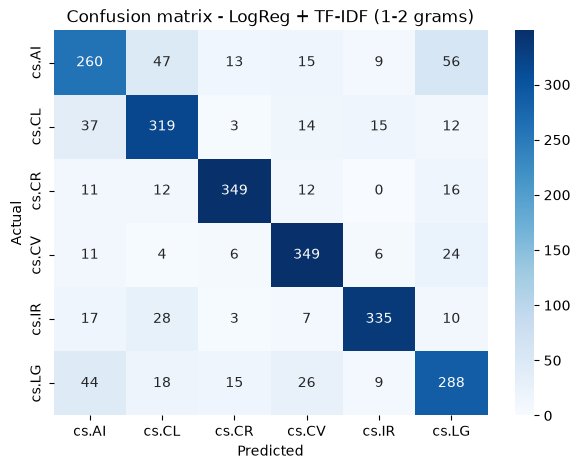

Saved artifacts/classifier.pkl -> NB06 uses classify.predict()


In [8]:
lr_cm = plot_confusion_matrix(y_test, lr_test_pred, "LogReg + TF-IDF (1-2 grams)")

path = clf.save_classifier(lr_pipeline)
print("Saved", path.relative_to(ARTIFACTS_DIR.parent), "-> NB06 uses classify.predict()")

### LogReg: confirming the setting on training data only

> **Justification.** The 1–2 gram setting was first chosen by looking at test scores, which makes that row slightly optimistic. Five-fold cross-validation on the 9,600 training papers repeats the choice without touching the test set, and also tries the regularisation strength C, which was left at its default.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for ngrams in [(1, 1), (1, 2), (1, 3)]:
    for c in [0.3, 1, 3, 10]:
        candidate = clf.build_tfidf_logreg(SEED).set_params(tfidf__ngram_range=ngrams, logreg__C=c)
        scores = cross_val_score(candidate, train_df["text"], y_train, cv=folds, scoring="f1_macro", n_jobs=4)
        cv_rows.append({"ngrams": str(ngrams), "C": c, "cv_macro_f1": round(scores.mean(), 3), "sd": round(scores.std(), 3)})

cv_table = pd.DataFrame(cv_rows).sort_values("cv_macro_f1", ascending=False)
results["logreg_cv"] = cv_rows
cv_table.head(5)


,ngrams,C,cv_macro_f1,sd
5,"(1, 2)",1.0,0.799,0.007
11,"(1, 3)",10.0,0.798,0.005
6,"(1, 2)",3.0,0.797,0.005
7,"(1, 2)",10.0,0.797,0.005
10,"(1, 3)",3.0,0.797,0.006


## Transformer or LLM classifier

Four advanced classifiers, each compared with the classical baseline above:
1. **Zero-shot NLI** (Week 7): no training; the model scores "This text is about {category name}" for each category.
2. **LSTM** (Week 6, lite): the simplified LSTM from the practical with a Hugging Face tokenizer, 2 epochs.
3. **DistilBERT** (Week 9, lite), both adaptation types from the lecture on the same 3,000 training papers: frozen [CLS] features + Logistic Regression, and a full fine-tune with Hugging Face `Trainer` for 1 epoch (GPU only).
4. **Few-shot LLM** (Week 9 prompting) through the team's `llm.generate`.

### Zero-shot NLI classifier (W7)

NLI model from the Week 7 practical (`sileod/deberta-v3-base-tasksource-nli`). Run twice: with the official category names as labels, and with one-line descriptions condensed from the arXiv taxonomy (`classify.CATEGORY_DESCRIPTIONS`).

> **Justification.** Zero-shot NLI (Week 7) needs no labelled data: each category becomes a hypothesis ("This paper is about ...") and the model picks the one it finds most entailed. It tells us what we would get if arXiv had no labels at all. The bare names worked badly because "Machine Learning" is true of almost every abstract, so the second run swaps in short descriptions and changes nothing else.

In [10]:
import json
from transformers import pipeline

zero_shot = pipeline("zero-shot-classification", model=ZERO_SHOT_MODEL, device=0 if HAS_GPU else -1)
zs_df = test_df.sample(n=ZERO_SHOT_N, random_state=SEED).reset_index(drop=True)


def run_zero_shot(labels, cache_name):
    """Top-scoring label for each of the 500 papers, cached because the CPU run takes ~7 min."""
    label_to_code = {name: code for code, name in labels.items()}
    cache = ARTIFACTS_DIR / cache_name
    meta = {"model": ZERO_SHOT_MODEL, "hypothesis_template": "This paper is about {}.", "labels": labels, "seed": SEED}
    if cache.exists():                       # keyed by paper id, and only reused if model/labels/template match
        saved = json.loads(cache.read_text())
        if {k: saved.get(k) for k in meta} == meta and set(saved["pred"]) == set(zs_df["id"]):
            print("Loaded cached zero-shot predictions:", cache_name)
            return [saved["pred"][pid] for pid in zs_df["id"]]
        print("Cache does not match this run; recomputing:", cache_name)
    pred = []
    start = time.time()
    for i, text in enumerate(zs_df["text"]):
        # "This paper is about {}." fits research abstracts better than the default "This example is {}."
        result = zero_shot(clf.shorten(text, 1500), list(label_to_code),
                           hypothesis_template="This paper is about {}.", multi_label=False)
        pred.append(label_to_code[result["labels"][0]])
        if (i + 1) % 100 == 0:
            print(f"{i + 1}/{ZERO_SHOT_N} done ({time.time() - start:.0f} s)")
    cache.write_text(json.dumps(meta | {"pred": dict(zip(zs_df["id"], pred))}, indent=1))
    return pred


zs_pred = run_zero_shot(clf.CATEGORY_NAMES, "03_zero_shot_pred.json")
zs_desc_pred = run_zero_shot(clf.CATEGORY_DESCRIPTIONS, "03_zero_shot_desc_pred.json")
zs_rows = [
    evaluate(zs_df["primary_category"], zs_pred, "Zero-shot NLI, category names", f"{ZERO_SHOT_N}-paper subset"),
    evaluate(zs_df["primary_category"], zs_desc_pred, "Zero-shot NLI, category descriptions", f"{ZERO_SHOT_N}-paper subset"),
]
results["models"].extend(zs_rows)
pd.DataFrame(zs_rows)

/home/guille/Study/University/Semester 3/COMP8460 NLP/Assignment 3/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loaded cached zero-shot predictions: 03_zero_shot_pred.json
Loaded cached zero-shot predictions: 03_zero_shot_desc_pred.json


,model,test_papers,accuracy,macro_precision,macro_recall,macro_f1,note
0,"Zero-shot NLI, category names",500,0.366,0.601,0.372,0.356,500-paper subset
1,"Zero-shot NLI, category descriptions",500,0.616,0.711,0.615,0.628,500-paper subset


### LSTM (W6, lite)

> **Justification.** The Week 6 LSTM is the first model here that reads words in order instead of as a bag. It learns its embeddings from scratch on 9,600 abstracts, so it shows how far a small sequence model gets without pre-training. Only two epochs ("lite"). It mean-pools over real tokens instead of using the practical's last hidden state, which had mostly seen padding.

In [11]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer

device = torch.device("cuda" if HAS_GPU else "cpu")
tokenizer = AutoTokenizer.from_pretrained(DISTILBERT)
label2id = {code: i for i, code in enumerate(CATEGORIES)}
id2label = {i: code for code, i in label2id.items()}


def encode(texts, labels, max_length=256):
    """Tokenise with the Hugging Face tokenizer (Week 6, 2.2) and pack ids + labels into a TensorDataset."""
    tokens = tokenizer(list(texts), padding="max_length", truncation=True,
                       max_length=max_length, return_tensors="pt")
    label_ids = torch.tensor([label2id[label] for label in labels])
    return TensorDataset(tokens["input_ids"], label_ids)


lstm_train = encode(train_df["text"], y_train)
lstm_test = encode(test_df["text"], y_test)
print("train:", len(lstm_train), "test:", len(lstm_test))

train: 9600 test: 2400


In [12]:
class LSTMClassifier(nn.Module):
    """Week 6 simplified LSTM, changed from 1 sigmoid output to 6 class scores."""

    def __init__(self, vocab_size, num_classes, embedding_dim=128, hidden_dim=64, num_layers=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers, batch_first=True, dropout=0.2)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids):
        embedded = self.embedding(input_ids)
        lstm_out, _ = self.lstm(embedded)
        # Mean-pool over real tokens only. Abstracts are right-padded to 256, so the final hidden
        # state (used in the practical) has read 100+ PAD tokens and forgets the text -> near-random accuracy.
        mask = (input_ids != tokenizer.pad_token_id).unsqueeze(-1).float()
        pooled = (lstm_out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.classifier(self.dropout(pooled))   # raw scores; CrossEntropyLoss applies softmax


lstm = LSTMClassifier(vocab_size=len(tokenizer), num_classes=len(CATEGORIES)).to(device)
optimizer = optim.Adam(lstm.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
train_loader = DataLoader(lstm_train, batch_size=32, shuffle=True)
test_loader = DataLoader(lstm_test, batch_size=64)

for epoch in range(2):
    lstm.train()
    total_loss, correct, seen = 0.0, 0, 0
    for input_ids, labels in train_loader:
        input_ids, labels = input_ids.to(device), labels.to(device)
        optimizer.zero_grad()
        scores = lstm(input_ids)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (scores.argmax(dim=1) == labels).sum().item()
        seen += labels.size(0)
    print(f"Epoch {epoch + 1}/2: loss = {total_loss / len(train_loader):.4f}, train accuracy = {correct / seen:.3f}")

lstm.eval()
lstm_pred = []
with torch.no_grad():
    for input_ids, labels in test_loader:
        scores = lstm(input_ids.to(device))
        lstm_pred.extend(id2label[i] for i in scores.argmax(dim=1).cpu().tolist())

lstm_row = evaluate(y_test, lstm_pred, "LSTM (2 epochs)")
results["models"].append(lstm_row)
lstm_row

Epoch 1/2: loss = 1.4529, train accuracy = 0.403
Epoch 2/2: loss = 0.9120, train accuracy = 0.669


{'model': 'LSTM (2 epochs)',
 'test_papers': 2400,
 'accuracy': 0.669,
 'macro_precision': 0.681,
 'macro_recall': 0.669,
 'macro_f1': 0.671}

### LSTM: does longer training change the result?

> **Justification.** Two epochs was a scope limit from the team plan, and the model was still improving when it stopped. So we check whether longer training changes the ranking. The epoch is chosen on 10% of the training papers, never on the test set, then the model is retrained on all 9,600. Seeds 1 and 2 are only there to show the spread between seeds.

In [13]:
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

CHECK_SEEDS = [42, 1, 2]
MAX_EPOCHS = 20


def lstm_scores(model, loader):
    model.eval()
    pred, gold = [], []
    with torch.no_grad():
        for input_ids, labels in loader:
            pred.extend(model(input_ids.to(device)).argmax(dim=1).cpu().tolist())
            gold.extend(labels.tolist())
    return accuracy_score(gold, pred), f1_score(gold, pred, average="macro")


def train_lstm(train_data, epochs, seed, val_loader=None):
    """Same model and optimiser as the cell above. Returns one row of scores per epoch."""
    torch.manual_seed(seed)
    model = LSTMClassifier(vocab_size=len(tokenizer), num_classes=len(CATEGORIES)).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    loader = DataLoader(train_data, batch_size=32, shuffle=True)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        correct, seen = 0, 0
        for input_ids, labels in loader:
            input_ids, labels = input_ids.to(device), labels.to(device)
            optimizer.zero_grad()
            scores = model(input_ids)
            criterion(scores, labels).backward()
            optimizer.step()
            correct += (scores.argmax(dim=1) == labels).sum().item()
            seen += labels.size(0)
        row = {"seed": seed, "epoch": epoch, "train_accuracy": correct / seen}
        if val_loader is not None:
            row["val_macro_f1"] = lstm_scores(model, val_loader)[1]
        row["test_accuracy"], row["test_macro_f1"] = lstm_scores(model, test_loader)
        history.append(row)
    return history


# fork_rng: these extra runs must not change the random numbers the later cells receive
with torch.random.fork_rng():
    tuning = []
    for seed in CHECK_SEEDS:
        fit_idx, val_idx = train_test_split(np.arange(len(lstm_train)), test_size=0.1,
                                            random_state=seed, stratify=y_train)
        val_loader = DataLoader(Subset(lstm_train, val_idx), batch_size=64)
        tuning += train_lstm(Subset(lstm_train, fit_idx), MAX_EPOCHS, seed, val_loader)
    tuning = pd.DataFrame(tuning)
    best_epochs = tuning.loc[tuning.groupby("seed")["val_macro_f1"].idxmax(), "epoch"].tolist()
    chosen_epoch = int(np.median(best_epochs))

    # Retrain on all 9,600 papers, as the other models were
    final = pd.DataFrame([row for seed in CHECK_SEEDS for row in train_lstm(lstm_train, chosen_epoch, seed)])

at_chosen = final[final["epoch"] == chosen_epoch]
at_two = final[final["epoch"] == 2]
results["lstm_epoch_check"] = {
    "best_epoch_per_seed": best_epochs,
    "chosen_epoch": chosen_epoch,
    "test_accuracy_mean": float(round(at_chosen["test_accuracy"].mean(), 3)),
    "test_macro_f1_mean": float(round(at_chosen["test_macro_f1"].mean(), 3)),
    "test_accuracy_by_seed": at_chosen["test_accuracy"].round(3).tolist(),
    "test_macro_f1_by_seed": at_chosen["test_macro_f1"].round(3).tolist(),
    "epoch_2_test_accuracy_by_seed": at_two["test_accuracy"].round(3).tolist(),
    "epoch_20_mean_train_accuracy": float(round(tuning[tuning["epoch"] == MAX_EPOCHS]["train_accuracy"].mean(), 3)),
    "epoch_20_mean_test_macro_f1": float(round(tuning[tuning["epoch"] == MAX_EPOCHS]["test_macro_f1"].mean(), 3)),
    "best_test_macro_f1_any_run": float(round(max(tuning["test_macro_f1"].max(), final["test_macro_f1"].max()), 3)),
}
print(results["lstm_epoch_check"])
tuning.groupby("epoch")[["train_accuracy", "val_macro_f1", "test_macro_f1"]].mean().round(3)

{'best_epoch_per_seed': [4, 5, 6], 'chosen_epoch': 5, 'test_accuracy_mean': 0.711, 'test_macro_f1_mean': 0.712, 'test_accuracy_by_seed': [0.71, 0.725, 0.697], 'test_macro_f1_by_seed': [0.715, 0.722, 0.697], 'epoch_2_test_accuracy_by_seed': [0.65, 0.694, 0.597], 'epoch_20_mean_train_accuracy': 0.98, 'epoch_20_mean_test_macro_f1': 0.704, 'best_test_macro_f1_any_run': 0.727}


,train_accuracy,val_macro_f1,test_macro_f1
epoch,,,
1,0.369,0.515,0.505
2,0.627,0.632,0.616
3,0.722,0.686,0.677
4,0.783,0.722,0.700
5,0.818,0.717,0.702
6,0.848,0.717,0.700
7,0.872,0.713,0.704
8,0.897,0.720,0.709
9,0.911,0.709,0.703


### DistilBERT: feature extraction vs full fine-tune (W9, lite)

> **Justification.** Week 9 covers two ways to adapt a pre-trained model: feature extraction (freeze the body, train a classifier on top) and full fine-tuning (update every weight). Both run on the same 3,000 papers, next to a LogReg trained on those same 3,000, so the three rows differ only in the model. DistilBERT is the small BERT from the practicals; one epoch takes under a minute on a laptop GPU.

In [14]:
from datasets import Dataset
from transformers import AutoModelForSequenceClassification, AutoModel, Trainer, TrainingArguments

ft_train_df = train_df.groupby("primary_category", group_keys=False).sample(
    n=FINETUNE_TRAIN_N // len(CATEGORIES), random_state=SEED)          # 500 per category = 3,000
distilbert_rows = []
distilbert_probs = None

# The classical pipeline on the same 3,000 papers, so the comparison is about the model, not the data size
lr_3k = clf.build_tfidf_logreg(SEED).fit(ft_train_df["text"], ft_train_df["primary_category"])
distilbert_rows.append(evaluate(y_test, lr_3k.predict(test_df["text"]), f"LogReg + TF-IDF ({len(ft_train_df)} train)"))

# (a) Feature extraction: DistilBERT frozen, its [CLS] vector goes into Logistic Regression
encoder = AutoModel.from_pretrained(DISTILBERT).to(device).eval()


def cls_vectors(texts, batch_size=32):
    vectors = []
    texts = list(texts)
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                              max_length=256, return_tensors="pt").to(device)
            vectors.append(encoder(**batch).last_hidden_state[:, 0].cpu().numpy())
    return np.vstack(vectors)


frozen_lr = LogisticRegression(max_iter=2000, random_state=SEED).fit(
    cls_vectors(ft_train_df["text"]), ft_train_df["primary_category"])
frozen_pred = frozen_lr.predict(cls_vectors(test_df["text"]))
distilbert_rows.append(evaluate(y_test, frozen_pred, f"DistilBERT frozen + LogReg ({len(ft_train_df)} train)"))
del encoder

# (b) Full fine-tune with Trainer, every weight updated (GPU only; about 1 min on an RTX 4060)
if HAS_GPU:
    def tokenize_function(examples):
        return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=256)

    def to_dataset(frame):
        data = Dataset.from_pandas(pd.DataFrame({
            "text": frame["text"].tolist(),
            "labels": [label2id[c] for c in frame["primary_category"]]}))
        return data.map(tokenize_function, batched=True)

    tokenized_train = to_dataset(ft_train_df)
    tokenized_test = to_dataset(test_df)

    model = AutoModelForSequenceClassification.from_pretrained(
        DISTILBERT, num_labels=len(CATEGORIES), id2label=id2label, label2id=label2id)
    training_args = TrainingArguments(
        output_dir=str(ARTIFACTS_DIR / "models" / "distilbert_runs"),
        num_train_epochs=1, per_device_train_batch_size=16, per_device_eval_batch_size=64,
        learning_rate=5e-5, weight_decay=0.01, logging_steps=50,
        eval_strategy="no", save_strategy="no", report_to="none", seed=SEED)
    trainer = Trainer(model=model, args=training_args, train_dataset=tokenized_train)

    start = time.time()
    trainer.train()
    print(f"Fine-tuning took {time.time() - start:.0f} s")

    logits = trainer.predict(tokenized_test).predictions
    distilbert_probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    distilbert_pred = [id2label[i] for i in logits.argmax(axis=1)]
    model.save_pretrained(ARTIFACTS_DIR / "models" / "distilbert")
    tokenizer.save_pretrained(ARTIFACTS_DIR / "models" / "distilbert")
    distilbert_rows.append(evaluate(y_test, distilbert_pred, f"DistilBERT fine-tuned (1 epoch, {len(ft_train_df)} train)"))
else:
    print("No GPU: full fine-tune skipped, only the frozen-feature row is reported")

results["models"].extend(distilbert_rows)
pd.DataFrame(distilbert_rows)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2400 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '1.498', 'grad_norm': '4.447', 'learning_rate': '3.697e-05', 'epoch': '0.266'}
{'loss': '0.9367', 'grad_norm': '2.757', 'learning_rate': '2.367e-05', 'epoch': '0.5319'}
{'loss': '0.7309', 'grad_norm': '6.552', 'learning_rate': '1.037e-05', 'epoch': '0.7979'}
{'train_runtime': '51.17', 'train_samples_per_second': '58.63', 'train_steps_per_second': '3.674', 'train_loss': '0.985', 'epoch': '1'}
Fine-tuning took 51 s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,model,test_papers,accuracy,macro_precision,macro_recall,macro_f1
0,LogReg + TF-IDF (3000 train),2400,0.777,0.778,0.777,0.777
1,DistilBERT frozen + LogReg (3000 train),2400,0.717,0.717,0.717,0.717
2,"DistilBERT fine-tuned (1 epoch, 3000 train)",2400,0.758,0.754,0.758,0.753


### Few-shot LLM classifier (W9 prompting)

The prompt lists the six arXiv category names, then gives one worked example per category taken from the **training** set, then the test paper. The reply is parsed for a category code; an unparseable reply counts as wrong. Same two label variants as zero-shot: official names vs short descriptions.

> **Justification.** Few-shot prompting (Week 9) tests whether a general instruction-tuned LLM, the same Qwen2.5-1.5B the rest of the system uses, can classify from one example per category with no training. The cost is speed: each paper needs a full LLM generation (seconds on a laptop GPU, not re-timed in the final run because replies came from the cache) against a fraction of a millisecond for LogReg. Replies are parsed for a category code, and anything unparseable counts as wrong.

In [15]:
import llm
print("LLM backend:", llm.describe())

examples = []
for category in CATEGORIES:
    example = train_df[y_train == category].sample(n=1, random_state=SEED).iloc[0]
    examples.append((example["text"], category))

llm_df = test_df.sample(n=LLM_N, random_state=SEED).reset_index(drop=True)
print(clf.build_few_shot_prompt(llm_df.loc[0, "text"], examples)[:1500], "...")

LLM backend: {'backend': 'hf', 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
Categories:
- cs.AI: Artificial Intelligence
- cs.CL: Computation and Language (natural language processing)
- cs.CR: Cryptography and Security
- cs.CV: Computer Vision and Pattern Recognition
- cs.IR: Information Retrieval
- cs.LG: Machine Learning

Paper: The Digital Apprentice: A Framework for Human-Directed Agentic AI Development. Agentic AI deployments face a recurring design tension: heavy human oversight limits scale, while broad autonomy outruns accountability. Neither posture provides the governance infrastructure required for responsible delegation. We present the Digital Apprentice, a framework for scalable, safe AI agency in which ...
Category: cs.AI

Paper: EvoCodeBench: An Evolving Code Generation Benchmark with Domain-Specific Evaluations. How to evaluate Large Language Models (LLMs) in code generation remains an open question. Existing benchmarks have two limitations - data leakage and lack of domain-

In [16]:
llm_rows = []
for describe in (False, True):
    llm_pred = []
    start = time.time()
    for i, text in enumerate(llm_df["text"]):
        llm_pred.append(clf.llm_classify(text, examples, describe=describe))
        if (i + 1) % 50 == 0:
            print(f"{i + 1}/{LLM_N} done ({time.time() - start:.0f} s)")

    unparsed = sum(1 for p in llm_pred if p is None)
    llm_pred_filled = [p if p is not None else "unparsed" for p in llm_pred]
    name = "Few-shot LLM, " + ("category descriptions" if describe else "category names")
    llm_rows.append(evaluate(llm_df["primary_category"], llm_pred_filled, name, f"{LLM_N}-paper subset, {unparsed} unparsed"))

results["models"].extend(llm_rows)
pd.DataFrame(llm_rows)

50/200 done (0 s)
100/200 done (0 s)
150/200 done (0 s)
200/200 done (0 s)
50/200 done (0 s)
100/200 done (0 s)
150/200 done (0 s)
200/200 done (0 s)


,model,test_papers,accuracy,macro_precision,macro_recall,macro_f1,note
0,"Few-shot LLM, category names",200,0.415,0.574,0.412,0.388,"200-paper subset, 0 unparsed"
1,"Few-shot LLM, category descriptions",200,0.485,0.602,0.473,0.469,"200-paper subset, 0 unparsed"


## Ensemble (optional)

Soft voting: average the class probabilities of two models and take the most likely class. LogReg + Naive Bayes always runs (both are cheap); LogReg + fine-tuned DistilBERT runs when the GPU fine-tune above produced probabilities.

> **Justification.** Soft voting averages two models' class probabilities, and it only helps when the models make different mistakes. NB and LogReg share the same features, so little gain is expected from that pair; LogReg + fine-tuned DistilBERT pairs a bag-of-words model with a contextual one, which is more likely to disagree usefully. Ensembles are on the spec's advanced list and in the Week 5 practical's list of improvements.

In [17]:
lr_probs = lr_pipeline.predict_proba(test_df["text"])           # columns follow lr_pipeline.classes_
nb_probs = nb_tfidf.predict_proba(X_test_tfidf)
assert list(lr_pipeline.classes_) == list(nb_tfidf.classes_) == CATEGORIES

ensemble_rows = []
avg = (lr_probs + nb_probs) / 2
ensemble_rows.append(evaluate(y_test, [CATEGORIES[i] for i in avg.argmax(axis=1)], "Ensemble: LogReg + NB"))

if distilbert_probs is not None:
    avg = (lr_probs + distilbert_probs) / 2
    ensemble_rows.append(evaluate(y_test, [CATEGORIES[i] for i in avg.argmax(axis=1)], "Ensemble: LogReg + DistilBERT"))

results["models"].extend(ensemble_rows)
pd.DataFrame(ensemble_rows)

,model,test_papers,accuracy,macro_precision,macro_recall,macro_f1
0,Ensemble: LogReg + NB,2400,0.792,0.791,0.792,0.791
1,Ensemble: LogReg + DistilBERT,2400,0.788,0.785,0.788,0.784


### DistilBERT: does more training or more data change the result?

> **Justification.** One epoch on 3,000 papers was a scope limit from the team plan, so this is the same check the LSTM got. The epoch is chosen on validation papers, never on the test set, up to the 4 epochs the BERT paper suggests. Each model is then retrained at that epoch with three seeds. LogReg uses every training paper, so the full-data run also tests whether the earlier ensemble was held back by a transformer trained on a third of the data. Takes about 15 min on an RTX 4060 (GPU only).

In [18]:
import gc

from scipy.stats import binomtest

BERT_MAX_EPOCHS = 4
BERT_SEEDS = [42, 1, 2]


def bert_metrics(eval_pred):
    return {"macro_f1": f1_score(eval_pred.label_ids, eval_pred.predictions.argmax(axis=1), average="macro")}


def finetune(train_data, epochs, seed, eval_sets):
    """Same settings as the fine-tune above; fp16 only makes it faster. Returns scores per epoch and test logits."""
    transformers.set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        DISTILBERT, num_labels=len(CATEGORIES), id2label=id2label, label2id=label2id)
    args = TrainingArguments(
        output_dir=str(ARTIFACTS_DIR / "models" / "distilbert_runs"),
        num_train_epochs=epochs, per_device_train_batch_size=16, per_device_eval_batch_size=64,
        learning_rate=5e-5, weight_decay=0.01, fp16=True, logging_strategy="no",
        eval_strategy="epoch", save_strategy="no", report_to="none", seed=seed, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_data, eval_dataset=eval_sets,
                      compute_metrics=bert_metrics)
    trainer.train()
    scores = {}
    for row in trainer.state.log_history:
        for key, value in row.items():
            if key.endswith("_macro_f1"):
                scores.setdefault(round(row["epoch"]), {"epoch": round(row["epoch"])})[key[5:]] = round(value, 3)
    logits = trainer.predict(eval_sets["test"]).predictions
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    return list(scores.values()), logits


def best_epoch(history):
    return max(history, key=lambda row: row["val_macro_f1"])["epoch"]


def mean_row(rows, name, n_note):
    """One table row from the three seeds."""
    keys = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
    return {"model": name, "test_papers": rows[0]["test_papers"], **{k: round(float(np.mean([r[k] for r in rows])), 3) for k in keys}, "note": n_note}


gold = y_test.to_numpy()
lr_pred = np.array(CATEGORIES)[lr_probs.argmax(axis=1)]
resamples = [np.random.default_rng(SEED + i).integers(0, len(gold), len(gold)) for i in range(2000)]


def compare_with_logreg(pred):
    """Macro-F1 gain over the 9,600-paper LogReg on the same papers, with a 95% bootstrap interval and McNemar's exact test."""
    macro = lambda p, idx: f1_score(gold[idx], p[idx], average="macro")
    gains = [macro(pred, idx) - macro(lr_pred, idx) for idx in resamples]
    only_lr, only_other = int(((lr_pred == gold) & (pred != gold)).sum()), int(((lr_pred != gold) & (pred == gold)).sum())
    return {"gain": round(f1_score(gold, pred, average="macro") - f1_score(gold, lr_pred, average="macro"), 3),
            "ci_95": [round(float(np.percentile(gains, q)), 3) for q in (2.5, 97.5)],
            "only_logreg_right": only_lr, "only_other_right": only_other,
            "mcnemar_p": round(binomtest(min(only_lr, only_other), only_lr + only_other, 0.5).pvalue, 3)}


if HAS_GPU:
    # Pick the epoch: 960 unused training papers for the 3,000-paper model, 10% of the training papers for the full model
    unused = train_df[~train_df["id"].isin(ft_train_df["id"])]
    val_unused = to_dataset(unused.groupby("primary_category", group_keys=False).sample(n=160, random_state=SEED))
    history_3k, _ = finetune(tokenized_train, BERT_MAX_EPOCHS, SEED, {"val": val_unused, "test": tokenized_test})

    fit_idx, val_idx = train_test_split(np.arange(len(train_df)), test_size=0.1, random_state=SEED, stratify=y_train)
    history_full, _ = finetune(to_dataset(train_df.iloc[fit_idx]), BERT_MAX_EPOCHS, SEED,
                               {"val": to_dataset(train_df.iloc[val_idx]), "test": tokenized_test})
    epochs_3k, epochs_full = best_epoch(history_3k), best_epoch(history_full)

    # Retrain at the chosen epoch, three seeds
    tokenized_full = to_dataset(train_df)
    seed_rows = []
    for train_name, train_data, epochs in [("3k", tokenized_train, epochs_3k), ("full", tokenized_full, epochs_full)]:
        for seed in BERT_SEEDS:
            _, logits = finetune(train_data, epochs, seed, {"test": tokenized_test})
            pred = np.array(CATEGORIES)[logits.argmax(axis=1)]
            row = evaluate(y_test, pred, f"DistilBERT {train_name} seed {seed}") | compare_with_logreg(pred)
            row.update(train=train_name, seed=seed, kind="DistilBERT")
            seed_rows.append(row)
            if train_name == "full":
                probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
                avg_pred = np.array(CATEGORIES)[((lr_probs + probs) / 2).argmax(axis=1)]
                row = evaluate(y_test, avg_pred, f"Ensemble seed {seed}") | compare_with_logreg(avg_pred)
                row.update(train=train_name, seed=seed, kind="Ensemble")
                seed_rows.append(row)

    seeds = pd.DataFrame(seed_rows)
    pick = lambda train, kind: [r for r in seed_rows if r["train"] == train and r["kind"] == kind]
    check_rows = [
        mean_row(pick("3k", "DistilBERT"), f"DistilBERT fine-tuned ({epochs_3k} epochs, 3000 train)", "mean of 3 seeds"),
        mean_row(pick("full", "DistilBERT"), f"DistilBERT fine-tuned ({epochs_full} epochs, 9600 train)", "mean of 3 seeds"),
        mean_row(pick("full", "Ensemble"), "Ensemble: LogReg + DistilBERT (9600 train)", "mean of 3 seeds"),
    ]
    results["models"].extend(check_rows)
    results["distilbert_check"] = {"history_3k": history_3k, "history_full": history_full,
                                   "chosen_epoch_3k": epochs_3k, "chosen_epoch_full": epochs_full, "by_seed": seed_rows}
    print(f"Epoch chosen on validation: {epochs_3k} on 3,000 papers, {epochs_full} on the full data")
    display(pd.DataFrame(history_3k).assign(train="3k"), pd.DataFrame(history_full).assign(train="full"))
    display(seeds[["kind", "train", "seed", "accuracy", "macro_f1", "gain", "ci_95", "mcnemar_p"]])
    display(pd.DataFrame(check_rows))
else:
    print("No GPU: longer fine-tune skipped")


Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'eval_val_loss': '0.6901', 'eval_val_macro_f1': '0.7602', 'eval_val_runtime': '1.732', 'eval_val_samples_per_second': '554.4', 'eval_val_steps_per_second': '8.663', 'epoch': '1'}
{'eval_test_loss': '0.7266', 'eval_test_macro_f1': '0.7434', 'eval_test_runtime': '4.314', 'eval_test_samples_per_second': '556.3', 'eval_test_steps_per_second': '8.807', 'epoch': '1'}
{'eval_val_loss': '0.6192', 'eval_val_macro_f1': '0.7966', 'eval_val_runtime': '1.737', 'eval_val_samples_per_second': '552.6', 'eval_val_steps_per_second': '8.634', 'epoch': '2'}
{'eval_test_loss': '0.6967', 'eval_test_macro_f1': '0.7638', 'eval_test_runtime': '4.336', 'eval_test_samples_per_second': '553.5', 'eval_test_steps_per_second': '8.763', 'epoch': '2'}
{'eval_val_loss': '0.6612', 'eval_val_macro_f1': '0.792', 'eval_val_runtime': '1.879', 'eval_val_samples_per_second': '511', 'eval_val_steps_per_second': '7.984', 'epoch': '3'}
{'eval_test_loss': '0.7269', 'eval_test_macro_f1': '0.771', 'eval_test_runtime': '4.559', 'ev

Map:   0%|          | 0/8640 [00:00<?, ? examples/s]

Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (14 outputs left out)

,epoch,val_macro_f1,test_macro_f1,train
0,1,0.760,0.743,3k
1,2,0.797,0.764,3k
2,3,0.792,0.771,3k
3,4,0.790,0.776,3k


,epoch,val_macro_f1,test_macro_f1,train
0,1,0.784,0.783,full
1,2,0.786,0.796,full
2,3,0.782,0.796,full
3,4,0.781,0.801,full


,kind,train,seed,accuracy,macro_f1,gain,ci_95,mcnemar_p
0,DistilBERT,3k,42,0.772,0.769,-0.023,"[-0.038, -0.009]",0.012
1,DistilBERT,3k,1,0.774,0.772,-0.020,"[-0.036, -0.004]",0.028
2,DistilBERT,3k,2,0.781,0.780,-0.011,"[-0.027, 0.004]",0.195
3,DistilBERT,full,42,0.797,0.797,0.005,"[-0.009, 0.019]",0.498
4,Ensemble,full,42,0.810,0.810,0.018,"[0.006, 0.031]",0.004
5,DistilBERT,full,1,0.803,0.802,0.011,"[-0.003, 0.024]",0.113
6,Ensemble,full,1,0.807,0.806,0.015,"[0.002, 0.027]",0.020
7,DistilBERT,full,2,0.795,0.794,0.002,"[-0.012, 0.016]",0.644
8,Ensemble,full,2,0.800,0.799,0.008,"[-0.005, 0.021]",0.198


,model,test_papers,accuracy,macro_precision,macro_recall,macro_f1,note
0,"DistilBERT fine-tuned (2 epochs, 3000 train)",2400,0.776,0.774,0.776,0.774,mean of 3 seeds
1,"DistilBERT fine-tuned (2 epochs, 9600 train)",2400,0.798,0.798,0.798,0.798,mean of 3 seeds
2,Ensemble: LogReg + DistilBERT (9600 train),2400,0.806,0.806,0.806,0.805,mean of 3 seeds


## Comparison table and error analysis

The zero-shot and LLM rows use subsets, so the LogReg baseline is also scored on exactly the same subsets for a fair comparison.

> **Justification.** Zero-shot and few-shot ran on subsets, so LogReg is re-scored on exactly those papers; comparing a 500-paper number with a 2,400-paper one would not be fair. The confusion pairs and the cross-listed split test whether the errors come from the models or from the labels: 1,332 of the 2,400 test papers are listed under more than one category, and only one of them counts as correct.

In [19]:
lr_by_id = dict(zip(test_df["id"], lr_test_pred))
fair_rows = [
    evaluate(zs_df["primary_category"], [lr_by_id[i] for i in zs_df["id"]], f"LogReg (same {ZERO_SHOT_N} as zero-shot)", f"{ZERO_SHOT_N}-paper subset"),
    evaluate(llm_df["primary_category"], [lr_by_id[i] for i in llm_df["id"]], f"LogReg (same {LLM_N} as LLM)", f"{LLM_N}-paper subset"),
]
results["models"].extend(fair_rows)

comparison = pd.DataFrame(results["models"]).set_index("model")
comparison.sort_values("macro_f1", ascending=False)

,test_papers,accuracy,macro_precision,macro_recall,macro_f1,note
model,,,,,,
LogReg (same 200 as LLM),200,0.825,0.828,0.826,0.827,200-paper subset
LogReg (same 500 as zero-shot),500,0.814,0.815,0.812,0.813,500-paper subset
Ensemble: LogReg + DistilBERT (9600 train),2400,0.806,0.806,0.806,0.805,mean of 3 seeds
"DistilBERT fine-tuned (2 epochs, 9600 train)",2400,0.798,0.798,0.798,0.798,mean of 3 seeds
LogReg + TF-IDF (1-2 grams),2400,0.792,0.793,0.792,0.792,NaN
Ensemble: LogReg + NB,2400,0.792,0.791,0.792,0.791,NaN
LogReg + TF-IDF,2400,0.787,0.789,0.787,0.788,NaN
Ensemble: LogReg + DistilBERT,2400,0.788,0.785,0.788,0.784,NaN
LogReg + TF-IDF (3000 train),2400,0.777,0.778,0.777,0.777,NaN


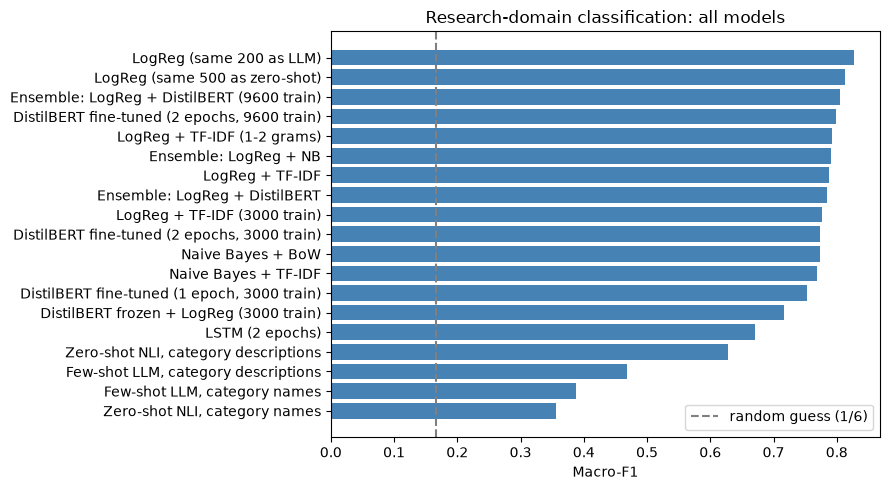

In [20]:
plot_table = comparison.sort_values("macro_f1")
plt.figure(figsize=(9, 5))
plt.barh(plot_table.index, plot_table["macro_f1"], color="steelblue")
plt.axvline(1 / len(CATEGORIES), color="grey", linestyle="--", label="random guess (1/6)")
plt.xlabel("Macro-F1")
plt.title("Research-domain classification: all models")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# Which domains get confused with each other? (off-diagonal cells of the LogReg confusion matrix)
pairs = []
for i, actual in enumerate(CATEGORIES):
    for j, predicted in enumerate(CATEGORIES):
        if i != j:
            pairs.append((actual, predicted, int(lr_cm[i, j])))
confused = pd.DataFrame(sorted(pairs, key=lambda p: -p[2])[:6], columns=["actual", "predicted", "papers"])
results["most_confused_pairs"] = confused.to_dict(orient="records")
confused

,actual,predicted,papers
0,cs.AI,cs.LG,56
1,cs.AI,cs.CL,47
2,cs.LG,cs.AI,44
3,cs.CL,cs.AI,37
4,cs.IR,cs.CL,28
5,cs.LG,cs.CV,26


In [22]:
# Cross-listing: are errors concentrated in papers listed under more than one category?
errors = test_df.assign(predicted=lr_test_pred)
errors["correct"] = errors["predicted"] == errors["primary_category"]
errors["cross_listed"] = errors["all_categories"].str.len() > 1
# "lenient" = the prediction is one of the paper's categories, even if not the primary one
errors["lenient_correct"] = [p in cats for p, cats in zip(errors["predicted"], errors["all_categories"])]

by_listing = errors.groupby("cross_listed")["correct"].agg(["count", "mean"]).round(3)
by_listing.index = ["single category", "cross-listed"]
results["accuracy_by_listing"] = by_listing["mean"].to_dict()
results["lenient_accuracy_logreg"] = round(float(errors["lenient_correct"].mean()), 3)
print("Strict accuracy :", round(float(errors["correct"].mean()), 3))
print("Lenient accuracy:", results["lenient_accuracy_logreg"], "(prediction is any of the paper's listed categories)")
by_listing

Strict accuracy : 0.792
Lenient accuracy: 0.875 (prediction is any of the paper's listed categories)


,count,mean
single category,1068,0.828
cross-listed,1332,0.763


In [23]:
# Three misclassified papers, to read by hand
for _, row in errors[~errors["correct"]].sample(n=3, random_state=SEED).iterrows():
    print(f"actual {row['primary_category']} | predicted {row['predicted']} | all categories {row['all_categories']}")
    print("  ", row["title"], "\n")

actual cs.AI | predicted cs.CL | all categories ['cs.AI', 'cs.CL']
   Systematic Generalization on gSCAN with Language Conditioned Embedding 

actual cs.CL | predicted cs.LG | all categories ['cs.CL', 'cs.LG']
   Interpretable phenotyping of Heart Failure patients with Dutch discharge letters 

actual cs.AI | predicted cs.CL | all categories ['cs.AI']
   Evaluating the Hidden Costs of Personalization in Large Language Models 



## Short input: does the classifier work on a query?

> **Justification.** The classifier was trained and scored on title + abstract, but the demo in NB06 gives it a short typed query. We have no labelled queries, so test-paper titles stand in for them: they are short, were never trained on, and have a known category. Titles are written carefully, so real queries may score lower.

In [24]:
title_pred = lr_pipeline.predict(test_df["title"])
title_words = test_df["title"].str.split().str.len()
short_rows = [evaluate(y_test, lr_test_pred, "LogReg, title + abstract"),
              evaluate(y_test, title_pred, "LogReg, title only")]
results["short_input_check"] = {"median_title_words": int(title_words.median()), "rows": short_rows}
print("Median title length:", int(title_words.median()), "words")
pd.DataFrame(short_rows)


Median title length: 9 words


,model,test_papers,accuracy,macro_precision,macro_recall,macro_f1
0,"LogReg, title + abstract",2400,0.792,0.793,0.792,0.792
1,"LogReg, title only",2400,0.690,0.716,0.690,0.698


## Findings and limitations

All scores below are **macro-F1** (accuracy in brackets where it differs). Rows marked "3 seeds" are means.
- **Kept model: TF-IDF (1–2 grams) + LogReg**, macro-F1 0.792 on all 2,400 test papers, saved to `classifier.pkl` for NB06. Cross-validation on the training papers picks the same setting (0.799), so the choice no longer rests on test scores.
- **Highest score: LogReg + DistilBERT ensemble**, 0.805 over 3 seeds (0.799–0.810). It beat LogReg clearly on two seeds and not on the third (McNemar p = 0.004, 0.020, 0.198). We keep LogReg: the gain is about 1.3 points, and the ensemble needs a GPU to train and a second model in the demo.
- **One epoch on 3,000 papers undersold DistilBERT.** On those 3,000 papers it goes from 0.753 to 0.774 at the 2 epochs chosen by validation, level with LogReg at 0.777. On all 9,600 papers it reaches 0.798 over 3 seeds (0.794–0.802), a tie with LogReg: no seed differs clearly. Frozen features stay at 0.717, so full fine-tuning beats feature extraction, as Week 9 predicts. Topic words carry most of the signal, which is why word counts keep up.
- **More LSTM epochs do not change the ranking.** The validation split picks epoch 5: macro-F1 0.712 on average over three seeds (0.697–0.722). After that train accuracy climbs to 0.98 while test macro-F1 stays near 0.70, so the extra epochs only over-fit.
- **For zero-shot, label wording mattered more than the model.** Swapping the arXiv names for one-line descriptions took zero-shot NLI from 0.356 to 0.628 and the few-shot LLM from 0.388 to 0.469. With the names, 298 of 500 zero-shot answers were cs.LG. Both remain well below LogReg on the same papers (0.813 and 0.827).
- **Many errors are label overlap, not model failure.** The top confusions are cs.AI ↔ cs.LG and cs.AI ↔ cs.CL. Cross-listed papers score 0.763 accuracy against 0.828 for single-category ones, and counting any listed category as correct lifts LogReg to 0.875 accuracy.
- **Short input costs about 10 points.** On test-paper titles (median 9 words) LogReg falls from 0.792 to 0.698. The classifier was built for papers, so its label on a short typed query is a rough guide only, and real queries may score lower than titles.
- **Limitations:** the category descriptions were chosen on test scores (they were written after the names failed on the same subsets), so both "descriptions" rows are slightly optimistic; zero-shot and few-shot ran on 500 and 200 papers, and differences under about 0.02 there are within noise; the DistilBERT epoch comes from one validation split of 960 papers, and all paired tests use one test set; titles only stand in for real queries; only one 1.5B LLM was tried; each paper gets one label although more than half have several; and GPU runs with one seed vary by up to 0.01 (LSTM, DistilBERT), while the LSTM at 2 epochs varies far more between seeds (accuracy 0.597–0.694).

In [25]:
path = save_results("03", results)
print("Saved", path.relative_to(ARTIFACTS_DIR.parent))
comparison

Saved artifacts/03_results.json


,test_papers,accuracy,macro_precision,macro_recall,macro_f1,note
model,,,,,,
Naive Bayes + BoW,2400,0.773,0.774,0.773,0.773,NaN
Naive Bayes + TF-IDF,2400,0.770,0.769,0.770,0.769,NaN
LogReg + TF-IDF,2400,0.787,0.789,0.787,0.788,NaN
LogReg + TF-IDF (1-2 grams),2400,0.792,0.793,0.792,0.792,NaN
"Zero-shot NLI, category names",500,0.366,0.601,0.372,0.356,500-paper subset
"Zero-shot NLI, category descriptions",500,0.616,0.711,0.615,0.628,500-paper subset
LSTM (2 epochs),2400,0.669,0.681,0.669,0.671,NaN
LogReg + TF-IDF (3000 train),2400,0.777,0.778,0.777,0.777,NaN
DistilBERT frozen + LogReg (3000 train),2400,0.717,0.717,0.717,0.717,NaN
